Tehtävä 14
Muodosta kohinainen signaali seuraavasti:

Toteutusesimerkki · Python / signaalin muodostaminen
import numpy as np
rng = np.random.default_rng(8)
t = np.arange(0, 100, 0.01)
clean_signal = np.sin(t) + np.sin(3*t - 1)
noisy_signal = clean_signal + 10*rng.random(len(t))
a) Piirrä puhdas ja kohinainen signaali samaan kuvaan.

b) Poista kohinaisen signaalin keskiarvo, laske Fourier-muunnos ja tunnista merkittävät taajuuskomponentit.

c) Suodata kohinaa Fourier-muunnoksen avulla ja palauta signaali käänteismuunnoksella. Vertaa tulosta tunnettuun puhtaaseen signaaliin.

d) Toista analyysi kirjan mukana toimitettavalle synteettiselle tiedostolle signal_to_be_cleaned.csv. Käytä näytteenottoväliä 1 s. Tunnista kolme hallitsevaa positiivista taajuutta ja piirrä puhdistettu signaali.

Toteutusesimerkki · CSV-aineiston lukeminen
Tiedostossa on sarakkeet time_s ja signal, pilkkuerotin ja desimaalipiste. Se on tätä kirjaa varten muodostettu harjoitusaineisto. Lue se esimerkiksi komennolla data = np.genfromtxt("koodi/data/signal_to_be_cleaned.csv", delimiter=",", names=True).

<function matplotlib.pyplot.show(close=None, block=None)>

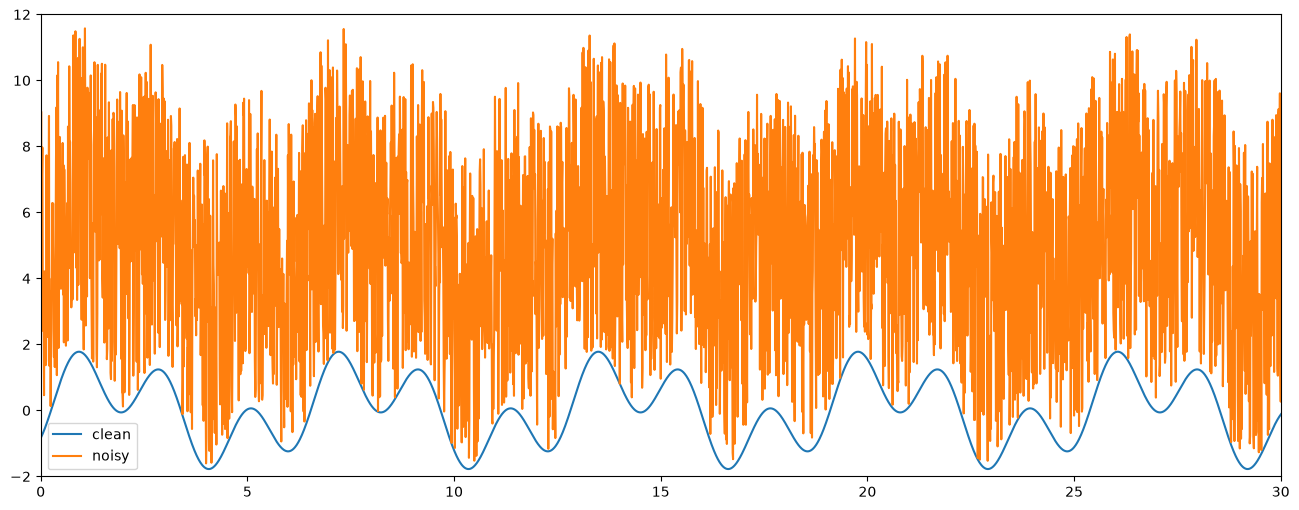

In [24]:
import numpy as np
import matplotlib.pyplot as plt

#a) Piirrä puhdas ja kohinainen signaali samaan kuvaan.

rng = np.random.default_rng(8)
dt = 0.01
t = np.arange(0, 100, dt)
clean_signal = np.sin(t) + np.sin(3*t - 1)
noisy_signal = clean_signal + 10*rng.random(len(t))

plt.figure(figsize=(16,6))
plt.plot(t, clean_signal, label="clean")
plt.plot(t, noisy_signal, label="noisy")
plt.axis([0,30,-2,12])
plt.legend()
plt.show

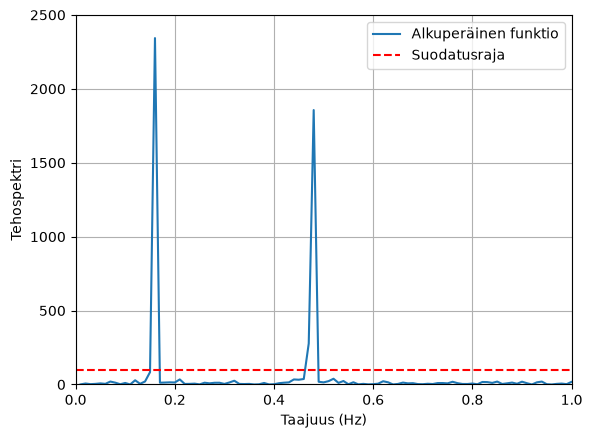

In [36]:
#b) Poista kohinaisen signaalin keskiarvo, laske Fourier-muunnos ja tunnista merkittävät taajuuskomponentit.
noisy_signal_avg = np.mean(noisy_signal)
f = noisy_signal - noisy_signal_avg     #funktio josta poistettu keskiarvo
N = len(f)

fourier = np.fft.fft(f, N)

psd = fourier*np.conj(fourier)/N

freq = np.fft.fftfreq(N,dt)
L = np.arange(1, np.floor(N/2), dtype='int') #Määritellään ne tehospektrin arvot, joita käytetään
PSD = np.array([freq[L], psd[L].real]) #Taajuudet ja tehospektrin arvot

plt.plot(PSD[0,:], PSD[1,:], label="Alkuperäinen funktio")
plt.xlabel("Taajuus (Hz)")
plt.ylabel("Tehospektri")
plt.axhline(100, color="red", linestyle="--", label="Suodatusraja")
plt.legend()
plt.grid()
plt.axis([0,1,0,2500])
plt.show()



Merkittävät taajuuskomponentit on:~ 0.18 ja 0.48


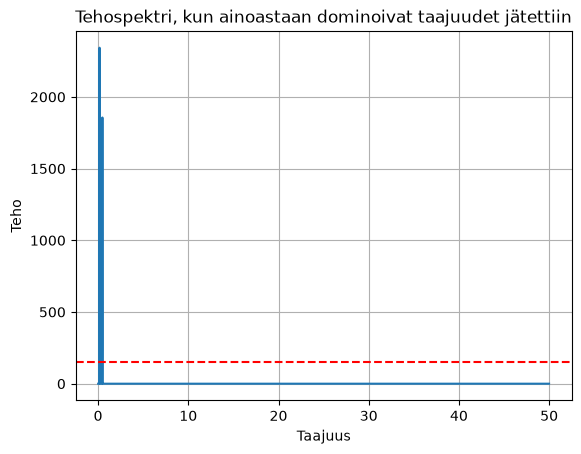

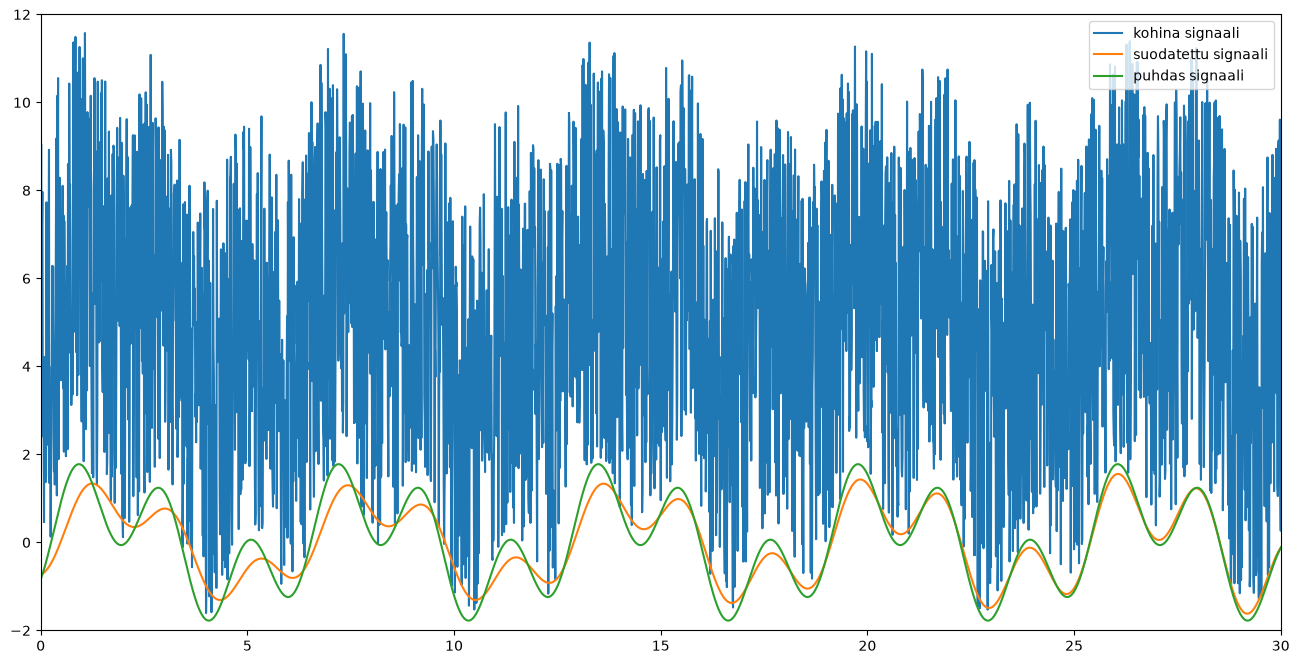

In [ ]:
#c) Suodata kohinaa Fourier-muunnoksen avulla ja palauta signaali käänteismuunnoksella. Vertaa tulosta tunnettuun puhtaaseen signaaliin.
fourier_dom = fourier.copy()
fourier_dom[psd<100] = 0
#testataan piirtämällä tehospektri
psd_dom = fourier*np.conj(fourier_dom)/N #Jokaisen rivin compleksiluvut kerrotaan kompleksikonjugaatillaan
PSD_dom = np.array([freq[L], psd_dom[L].real]) #Taajuudet ja tehospektrin arvot

plt.plot(PSD_dom[0,:], PSD_dom[1,:])
plt.title('Tehospektri, kun ainoastaan dominoivat taajuudet jätettiin')
plt.xlabel('Taajuus')
plt.ylabel('Teho')
plt.grid()
plt.show

#palautetaam signaali, jossa mukana ainoastaan dominoivat taajuudet
signal_dom = np.fft.ifft(fourier_dom).real
#plt.axhline(150, color="red", linestyle="--", label="Suodatusraja")

plt.figure(figsize=(16,8))
plt.plot(t,noisy_signal, label="kohina signaali")
plt.plot(t,signal_dom, label="suodatettu signaali")
plt.plot(t,clean_signal, label="puhdas signaali")
plt.axis([0,30,-2,12])
plt.legend()
plt.show()
